# TrustXRay — 01. Data exploration

**Goal of this notebook:** load the PneumoniaMNIST chest X-ray dataset, understand its structure and class balance, and look at real images before training any model.

**Dataset:** PneumoniaMNIST (MedMNIST v2), derived from 5,856 pediatric chest X-rays (Kermany et al., 2018). Binary task: `0 = normal`, `1 = pneumonia`. License: CC BY 4.0.

> Run this notebook in **Google Colab** (Runtime → Change runtime type → GPU is not needed yet).

In [1]:
!pip install -q medmnist

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.9/115.9 kB 5.3 MB/s eta 0:00:00


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import medmnist
from medmnist import INFO, PneumoniaMNIST

SIZE = 224                 # image resolution (28, 64, 128 or 224)
DATA_DIR = "./data"
FIG_DIR = "./figures"
os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(FIG_DIR, exist_ok=True)

info = INFO["pneumoniamnist"]
CLASS_NAMES = {int(k): v for k, v in info["label"].items()}
print("MedMNIST version:", medmnist.__version__)
print("Classes:", CLASS_NAMES)
print("License:", info["license"])

MedMNIST version: 3.0.2
Classes: {0: 'normal', 1: 'pneumonia'}
License: CC BY 4.0


## 1. Load the three splits (train / validation / test)

In [3]:
splits = {}
for split in ["train", "val", "test"]:
    ds = PneumoniaMNIST(split=split, download=True, size=SIZE, root=DATA_DIR)
    splits[split] = (ds.imgs, ds.labels.ravel())
    print(f"{split:5s} -> images {ds.imgs.shape}, labels {ds.labels.shape}")

100%|██████████| 214M/214M [00:37<00:00, 5.67MB/s]


train -> images (4708, 224, 224), labels (4708, 1)
val   -> images (524, 224, 224), labels (524, 1)
test  -> images (624, 224, 224), labels (624, 1)


## 2. Basic properties of the images

In [4]:
X_train, y_train = splits["train"]
print("dtype:", X_train.dtype)
print("pixel range:", X_train.min(), "->", X_train.max())
print("mean pixel value:", round(float(X_train.mean()), 2))
print("one image shape:", X_train[0].shape, "(grayscale, 1 channel)")

dtype: uint8
pixel range: 0 -> 255
mean pixel value: 145.77
one image shape: (224, 224) (grayscale, 1 channel)


## 3. Class distribution

In medicine, classes are rarely balanced. This matters for training (loss weighting) and for evaluation (accuracy can be misleading).

In [5]:
rows = []
for split, (X, y) in splits.items():
    n_normal = int((y == 0).sum())
    n_pneu = int((y == 1).sum())
    rows.append({"split": split, "normal": n_normal, "pneumonia": n_pneu,
                 "total": len(y), "% pneumonia": round(100 * n_pneu / len(y), 1)})
dist = pd.DataFrame(rows).set_index("split")
dist

,normal,pneumonia,total,% pneumonia
split,,,,
train,1214,3494,4708,74.2
val,135,389,524,74.2
test,234,390,624,62.5


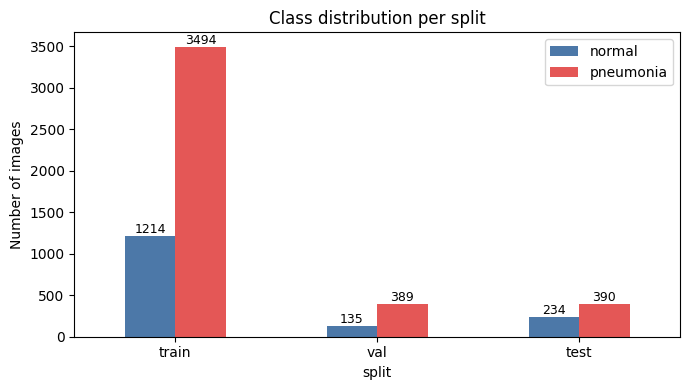

In [6]:
ax = dist[["normal", "pneumonia"]].plot(kind="bar", figsize=(7, 4),
                                        color=["#4C78A8", "#E45756"], rot=0)
ax.set_title("Class distribution per split")
ax.set_ylabel("Number of images")
for c in ax.containers:
    ax.bar_label(c, fontsize=9)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/class_distribution.png", dpi=150)
plt.show()

## 4. Look at real images

Always look at the data before modeling: image quality, orientation, text markers, borders...

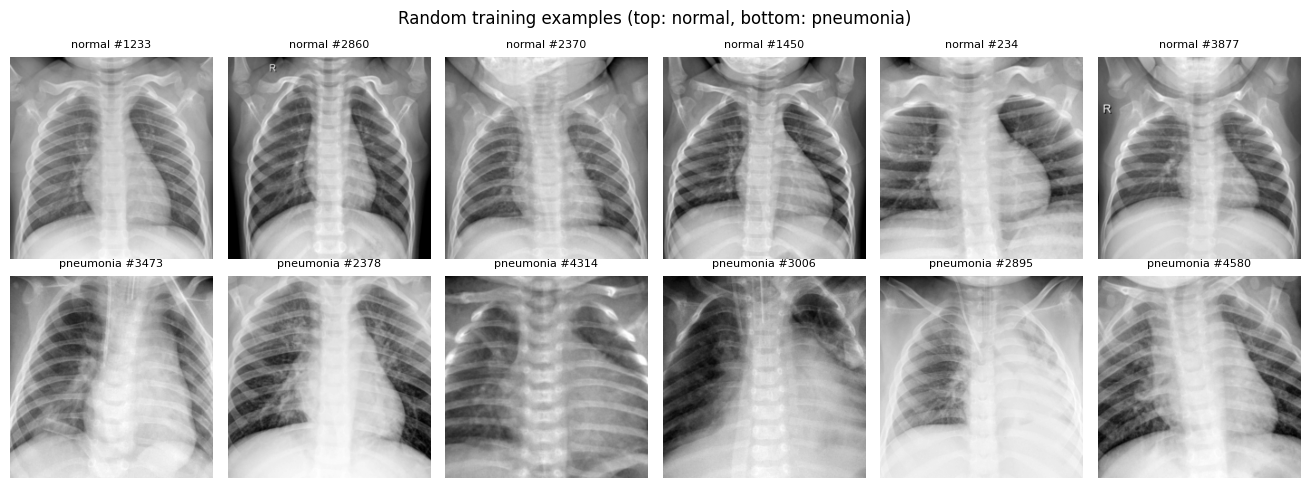

In [7]:
def show_examples(X, y, n_per_class=6, seed=0):
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(2, n_per_class, figsize=(2.2 * n_per_class, 5))
    for row, cls in enumerate([0, 1]):
        idx = rng.choice(np.where(y == cls)[0], n_per_class, replace=False)
        for col, i in enumerate(idx):
            axes[row, col].imshow(X[i], cmap="gray")
            axes[row, col].axis("off")
            axes[row, col].set_title(f"{CLASS_NAMES[cls]} #{i}", fontsize=8)
    plt.suptitle("Random training examples (top: normal, bottom: pneumonia)")
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/examples.png", dpi=150)
    plt.show()

show_examples(X_train, y_train)

## 5. Pixel intensity per class

Does pneumonia change the overall brightness of the image? (Opacities in the lungs often appear whiter.)

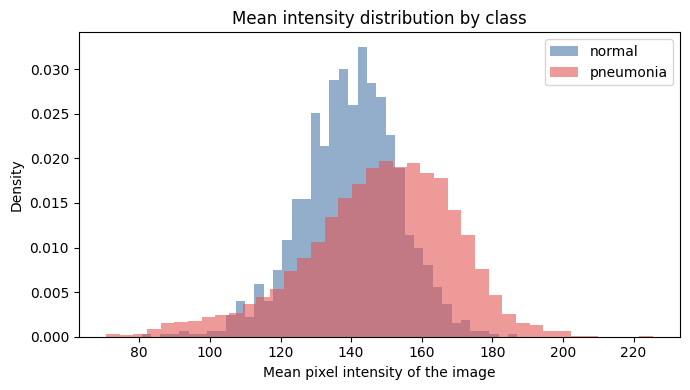

normal     mean intensity = 139.8
pneumonia  mean intensity = 147.9


In [8]:
mean_intensity = X_train.reshape(len(X_train), -1).mean(axis=1)
plt.figure(figsize=(7, 4))
for cls, color in [(0, "#4C78A8"), (1, "#E45756")]:
    plt.hist(mean_intensity[y_train == cls], bins=40, alpha=0.6,
             label=CLASS_NAMES[cls], color=color, density=True)
plt.xlabel("Mean pixel intensity of the image")
plt.ylabel("Density")
plt.title("Mean intensity distribution by class")
plt.legend()
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/intensity_by_class.png", dpi=150)
plt.show()

for cls in [0, 1]:
    print(f"{CLASS_NAMES[cls]:10s} mean intensity = {mean_intensity[y_train == cls].mean():.1f}")

## 6. What this means for training (used in notebook 02)

In [9]:
n_neg = int((y_train == 0).sum())
n_pos = int((y_train == 1).sum())
pos_weight = n_neg / n_pos
print(f"Imbalance ratio (pneumonia / normal): {n_pos / n_neg:.2f}")
print(f"pos_weight for BCEWithLogitsLoss: {pos_weight:.3f}")
print("Baseline 'always predict pneumonia' accuracy on test:",
      f"{100 * (splits['test'][1] == 1).mean():.1f}%  <- a model must beat this!")

Imbalance ratio (pneumonia / normal): 2.88
pos_weight for BCEWithLogitsLoss: 0.347
Baseline 'always predict pneumonia' accuracy on test: 62.5%  <- a model must beat this!


## 7. Observations

- **Class balance:** strong imbalance in train/val (74.2% pneumonia, ~3:1). The test set is less imbalanced (62.5% pneumonia) → distribution shift between splits; a model biased toward "pneumonia" will produce more false positives on test.
- **Baseline:** always predicting "pneumonia" already gives 62.5% test accuracy → accuracy alone is misleading; we will use recall, specificity and the confusion matrix.
- **Visual differences:** normal lungs are dark with sharp ribs; pneumonia shows whitish, blurry opacities in the lung fields.
- **Artifacts:** some images contain a laterality marker ("R") in the corner. A model could learn this shortcut instead of lung features → to be checked with Grad-CAM.
- **Limitations:** pediatric patients only (1–5 years), single hospital (Guangzhou), images resized/center-cropped → not clinically validated for adults or other hospitals.